# Sonification of Octahedral Tilt Amplitudes Part Two (discrete data)

For background and context please see [Part One](./Sonification_of_Octahedral_Tilts_Part_One.ipynb).

In [1]:
%reload_ext autoreload 
%autoreload 2
import matplotlib.pyplot as plt
#import ffmpeg as ff
#import wavio as wav
from strauss.sonification import Sonification
from strauss.sources import Events
from strauss import channels
from strauss.score import Score
import numpy as np
from strauss.generator import Sampler
import IPython.display as ipd
import os
import pathlib
%matplotlib inline

In [2]:
chords = [['C1','C#1','D1','D#1','E1','F1','F#1','G1','G#1','A1','A#1','B1','C2','C#2','D2','D#2','E2','F2','F#2','G2','G#2','A2','A#2','B2','C3','C#3','D3','D#3','E3','F3','F#3','G3','G#3','A3','A#3','B3','C4','C#4','D4','D#4','E4','F4','F#4','G4','G#4','A4','A#4','B4']]
length = 50
score =  Score(chords, length)

In [3]:
filename = '../data/df_heating_tric_Tstart1_Tstop1200_P0_size8_nsteps200_dump500_run-000.csv'
filename2 = '../data/df_heating_tric_Tstart1_Tstop1200_P1_size8_nsteps200_dump500_run-000.csv'
filename3 = '../data/df_cooling_tric_Tstart1200_Tstop1_P1_size8_nsteps200_dump500_run-000.csv'
filename4 = '../data/df_cooling_tric_Tstart1200_Tstop1_P0_size8_nsteps200_dump500_run-000.csv'
jump = int(1E3)

data_input = np.genfromtxt(filename, delimiter=',')[1:]
data_input2 = np.genfromtxt(filename2, delimiter=',')[1:]
data_input3 = np.genfromtxt(filename3, delimiter=',')[1:]
data_input4 = np.genfromtxt(filename4, delimiter=',')[1:]
time = data_input[:,0][::jump][:-90]
temp = data_input[:,1][::jump][:-90]
Mx = data_input[:,3][::jump][:-90]
My = data_input[:,4][::jump][:-90]
Mz = data_input[:,5][::jump][:-90]
Rx = data_input[:,6][::jump][:-90]
Ry = data_input[:,7][::jump][:-90]
Rz = data_input[:,8][::jump][:-90]
Mx2 = data_input2[:,3][::jump][:-70]
My2 = data_input2[:,4][::jump][:-70]
Mz2 = data_input2[:,5][::jump][:-70]
time2 = data_input2[:,0][::jump][:-70]
temp2 = data_input2[:,1][::jump][:-70]
Mx3 = data_input3[:,3][::jump][:-70]
My3 = data_input3[:,4][::jump][:-70]
Mz3 = data_input3[:,5][::jump][:-70]
time3 = data_input3[:,0][::jump][:-70]
temp3 = data_input3[:,1][::jump][:-70]
Mx4 = data_input4[:,3][::jump][:-70]
My4 = data_input4[:,4][::jump][:-70]
Mz4 = data_input4[:,5][::jump][:-70]
time4 = data_input4[:,0][::jump][:-70]
temp4 = data_input4[:,1][::jump][:-70]

data_Mz = {
        'azimuth': [90]*len(time),
        'polar': [45]*len(time),
        'time': temp,
        'pitch': Mz}

data_Ry = {
        'azimuth': [90]*len(time),
        'polar': [45]*len(time),
        'time': temp,
        'pitch': Ry}

data_Rx = {
        'azimuth': [90]*len(time),
        'polar': [45]*len(time),
        'time': temp,
        'pitch': Rx}

data_Rz = {
        'azimuth': [90]*len(time),
        'polar': [45]*len(time),
        'time': temp,
        'pitch': Rz}

data_My = {
        'azimuth': [270]*len(time),
        'polar': [45]*len(time),
        'time': temp,
        'pitch': My}

data_Mx = {
        'time': temp,
        'pitch': Mx}

mapvals = {
        'azimuth': lambda x: x,
        'polar': lambda x: x,
        'time': lambda x: x,
        'pitch': lambda x: x+1}

maplims =  {'azimuth': (0, 360),
            'polar': (0, 180), 
            'time': ('0', '104'),
            'pitch' : ('0','100'),
            'volume' : ('0', '100')}

paramlims = {'pitch' : (0, 0.3)}

events = Events(data_Mz.keys())
events.fromdict(data_Mz)
events.apply_mapping_functions(mapvals, maplims)

/var/folders/ny/5knc_9j57gx54mx6yn23ds200000gp/T/ipykernel_46673/2940112647.py:85: UserWarning: Specifying percentiles without appending a '%' character (e.g. XX%) currently works but is deprecated for more explicit syntax.
  events.apply_mapping_functions(mapvals, maplims)


In [4]:
sampler = Sampler(pathlib.Path("..", "data", "samples", "mallets"))  # or glockenspiels
sampler.preset_details("default")

default:
Default preset for the sampler, basic setup with no looping, and an on-off volume envelope.



In [5]:
system = "stereo"

In [6]:
soni = Sonification(score, events, sampler, system)
soni.render()

100%|████████████████████████████████████████| 310/310 [00:00<00:00, 471.53it/s]


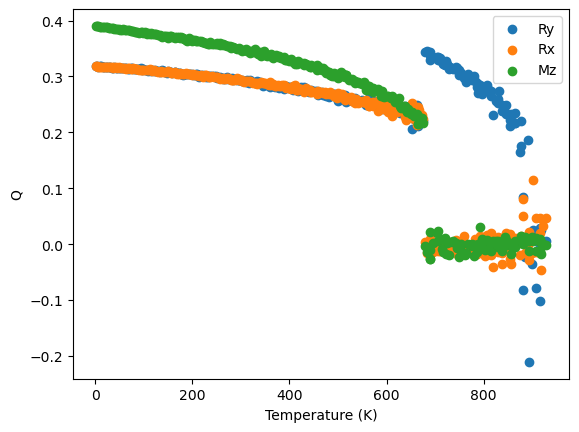

In [7]:
plt.scatter(temp, Ry,label='Ry')
plt.scatter(temp, Rx,label='Rx')
plt.scatter(temp, Mz,label='Mz')
plt.legend()
plt.xlabel('Temperature (K)')
plt.ylabel(r'Q')
#plt.xlim(1,2)
plt.show()

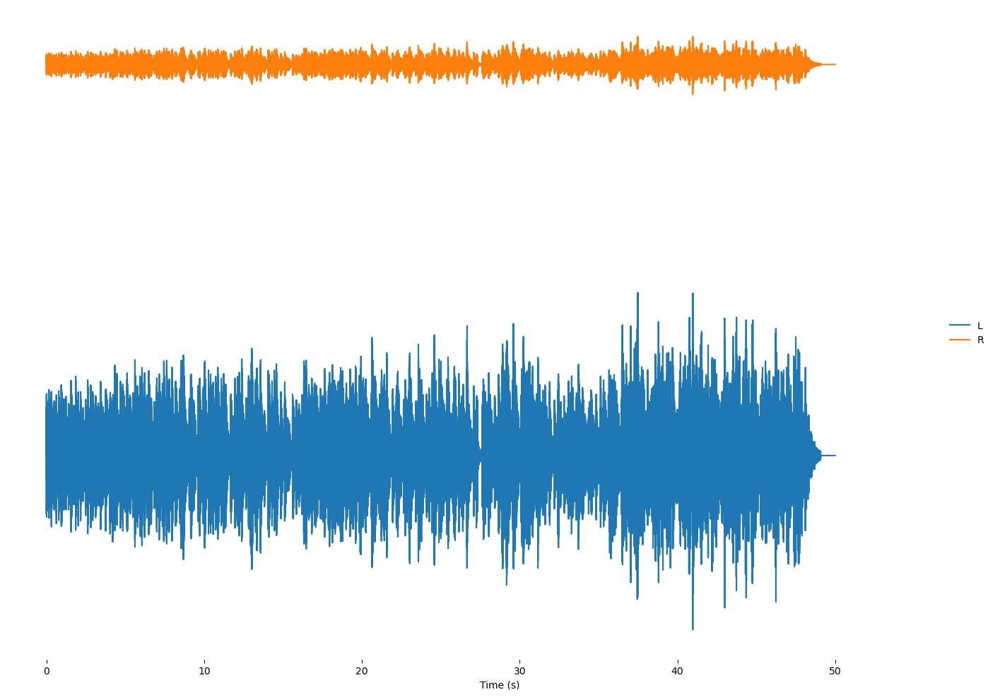

In [8]:
soni.notebook_display()

Listen to the sonification [here](https://NU-CEM.github.io/play_audio?p=https://github.com/lucydot/SingingMaterials_Dissemination/raw/refs/heads/main/assets/wav/BZS_M_discrete.wav) (note this version is 90s rather than 30s).


In [9]:
events2 = Events(data_Ry.keys())
events2.fromdict(data_Ry)
events2.apply_mapping_functions(mapvals, maplims, paramlims)
soni2 = Sonification(score, events2, sampler, system)
soni2.out_channels = soni.out_channels
soni2.render()

/var/folders/ny/5knc_9j57gx54mx6yn23ds200000gp/T/ipykernel_46673/3225632838.py:3: UserWarning: Specifying percentiles without appending a '%' character (e.g. XX%) currently works but is deprecated for more explicit syntax.
  events2.apply_mapping_functions(mapvals, maplims, paramlims)
100%|████████████████████████████████████████| 310/310 [00:00<00:00, 467.96it/s]


In [10]:
events3 = Events(data_Rx.keys())
events3.fromdict(data_Rx)
events3.apply_mapping_functions(mapvals, maplims, paramlims)
soni3 = Sonification(score, events3, sampler, system)
soni3.out_channels = soni2.out_channels
soni3.render()

/var/folders/ny/5knc_9j57gx54mx6yn23ds200000gp/T/ipykernel_46673/4180487488.py:3: UserWarning: Specifying percentiles without appending a '%' character (e.g. XX%) currently works but is deprecated for more explicit syntax.
  events3.apply_mapping_functions(mapvals, maplims, paramlims)
100%|████████████████████████████████████████| 310/310 [00:00<00:00, 479.80it/s]


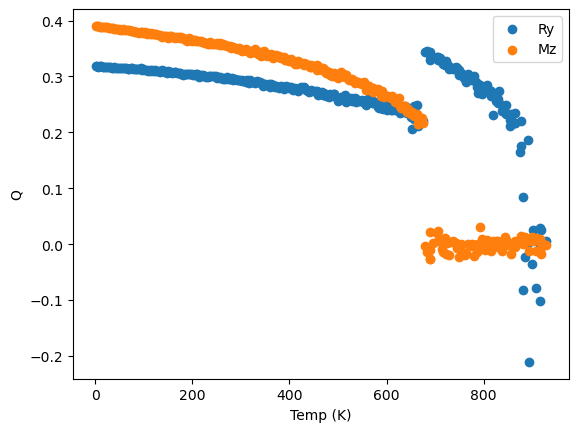

In [11]:
plt.scatter(temp, Ry,label='Ry')
plt.scatter(temp, Mz,label='Mz')
plt.legend()
plt.xlabel('Temp (K)')
plt.ylabel(r'Q')
plt.show()

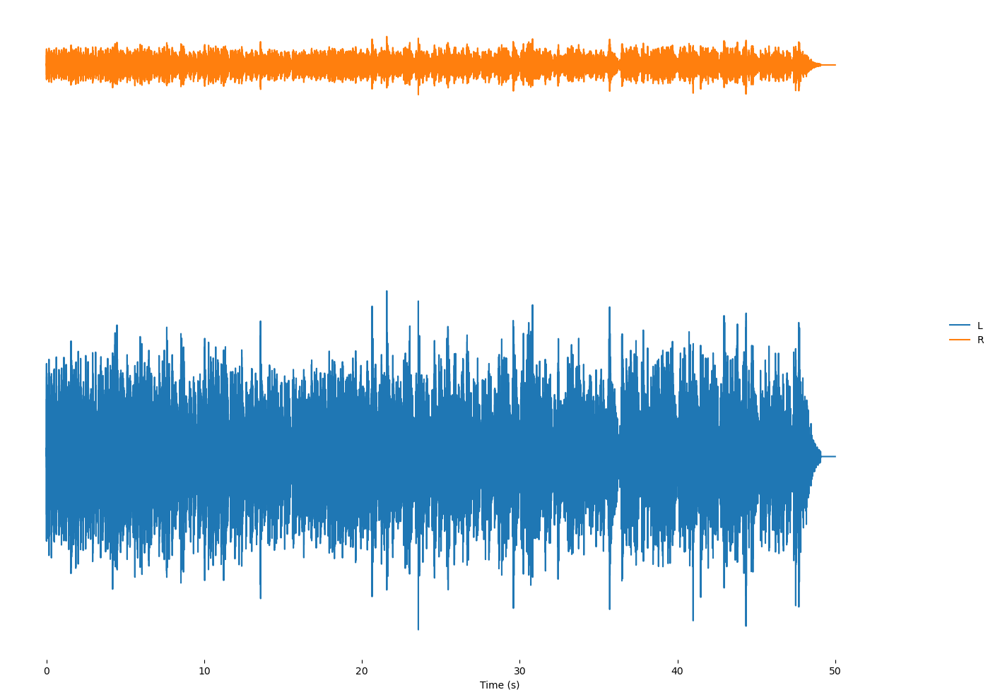

In [12]:
soni3.notebook_display()

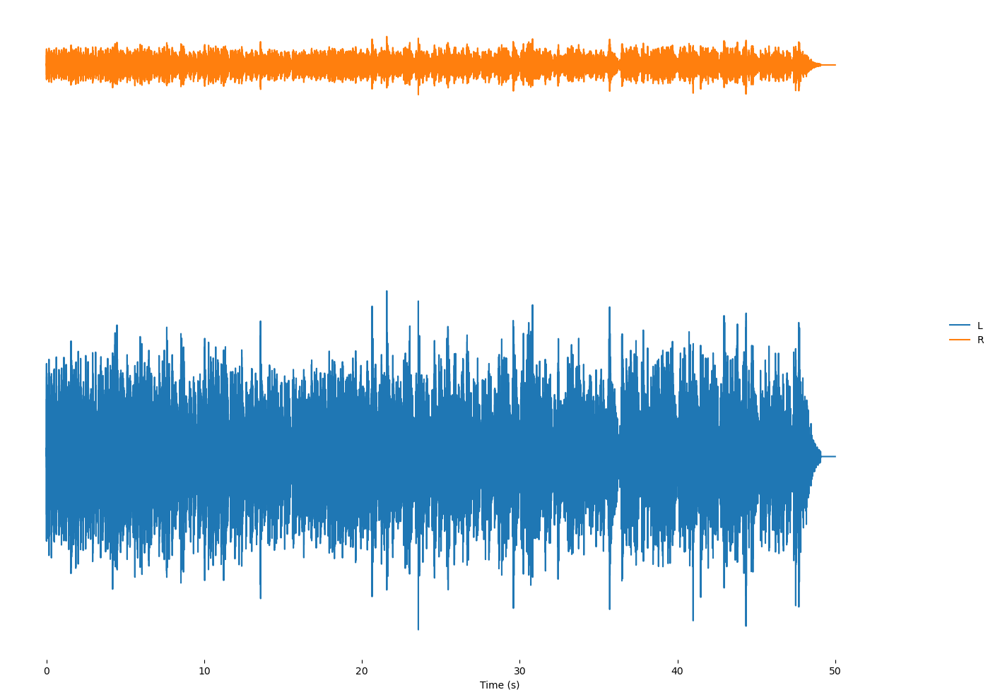

In [13]:
soni2.notebook_display()

Listen to the sonification [here](https://NU-CEM.github.io/play_audio?p=https://github.com/lucydot/SingingMaterials_Dissemination/raw/refs/heads/main/assets/wav/BZS_My_Mz_discrete.wav) (note this version is 90s rather than 30s).